# Mô hình dự đoán giá bất động sản bán tại TP.HCM

Notebook này trình bày đầy đủ quá trình xây dựng mô hình dự đoán giá bán (`price_model`) của hệ thống,
từ dữ liệu đã làm sạch trong Lakehouse đến mô hình cuối cùng được đưa vào pipeline
`scripts/train_price_model.py`. Mọi hàm biến đổi đặc trưng được import thẳng từ `scripts/price_features.py`,
nên kết quả ở đây chính là kết quả của pipeline thật.

**Nội dung**

1. Dữ liệu nguồn và quy trình làm sạch (tầng Silver → Gold)
2. Khám phá dữ liệu
3. Tiền xử lý và xây dựng đặc trưng
4. Chia dữ liệu theo thời gian
5. Mô hình cơ sở và cấu hình ban đầu
6. Lọc nhiễu tập huấn luyện
7. Dò siêu tham số bằng Optuna
8. Đánh giá trên tập kiểm tra
9. Một mô hình gộp hay mô hình riêng cho từng loại hình
10. Phân tích mô hình cuối cùng
11. Kết luận

**Chỉ số đánh giá.** Với $y_i$ là giá thật và $\hat y_i$ là giá dự đoán trên $n$ tin:

- $\text{MAPE} = \frac{1}{n}\sum_i \frac{|\hat y_i - y_i|}{y_i}$: sai số tương đối trung bình, chỉ số chính để chọn mô hình
  (dễ hiểu với người dùng: "lệch trung bình bao nhiêu phần trăm"), cũng là chỉ số của cổng chất lượng trong pipeline.
- **MdAPE**: trung vị của sai số tương đối, ít bị ảnh hưởng bởi vài tin sai rất nhiều.
- **Tỉ lệ tin sai ≤ 20%**: phần trăm tin có giá dự đoán nằm trong ±20% giá thật.

**Chạy lại:** cần MinIO (`docker compose up -d minio`) và các gói trong `.venv` (deltalake, xgboost, optuna).
Kết quả dò siêu tham số được lưu ra `optuna_wide_search.csv` và `optuna_narrow_search.csv`; khi hai file này có sẵn,
notebook đọc lại thay vì dò lại (dò lại từ đầu mất khoảng 45 phút).

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from deltalake import DeltaTable
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
from xgboost import XGBRegressor

sys.path.append("../scripts")  # dùng đúng mã biến đổi đặc trưng của pipeline
from price_features import AREA_COLUMNS, AREA_GROUPS, AreaPriceEncoder, PricePerM2Regressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titlelocation": "left"})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
TYPE_COLOR = {"Căn hộ/Chung cư": BLUE, "Nhà ở": ORANGE, "Đất": AQUA}  # màu theo loại hình, cố định

STORAGE = {
    "AWS_ENDPOINT_URL": os.getenv("MINIO_ENDPOINT", "http://localhost:9000"),
    "AWS_ACCESS_KEY_ID": os.getenv("MINIO_ACCESS_KEY", "minio"),
    "AWS_SECRET_ACCESS_KEY": os.getenv("MINIO_SECRET_KEY", "minio123"),
    "AWS_REGION": "us-east-1",
    "AWS_ALLOW_HTTP": "true",
}
WAREHOUSE = "s3://lakehouse/warehouse"


def read_delta(name, columns=None):
    table = DeltaTable(f"{WAREHOUSE}/{name}", storage_options=STORAGE)
    return table.to_pandas(columns=columns), table.version()

/home/theanh/Documents/KLTN/KLTN_LakeHouse_Real_Estate_ML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dữ liệu nguồn và quy trình làm sạch

Dữ liệu được thu thập hằng ngày từ Nhà Tốt và đi qua các tầng của Lakehouse:

| Tầng | Bảng | Xử lý chính |
|---|---|---|
| Bronze | `bronze.nhatot_*` | Dữ liệu thô từ API, lưu nguyên trạng |
| Silver | `silver.listing_current` | Chuẩn hoá kiểu dữ liệu, giá (tỷ → VND), diện tích, địa chỉ; tin lỗi định dạng bị chuyển sang `silver.listing_quarantine`; mỗi tin giữ trạng thái mới nhất |
| Gold | `gold.ml_price_features` | Lọc tin đủ điều kiện huấn luyện, bỏ ngoại lai, bỏ tin sai vị trí, gộp tin trùng (mô hình dbt `ml_price_features.sql`) |

Ô dưới đây tái hiện lại bằng pandas từng bước lọc của dbt, đi từ `silver.listing_current` đến bảng đặc trưng,
để thấy mỗi quy tắc loại bao nhiêu tin. Bảng cuối được đối chiếu với số dòng thật của `gold.ml_price_features`.

| Bước | Quy tắc | Lý do |
|---|---|---|
| 1 | Chỉ giữ tin **bán** | Mô hình dự đoán giá bán; giá thuê là bài toán khác |
| 2 | Giá > 0, diện tích > 0, thuộc TP.HCM, có quận và loại hình | Thiếu các trường này thì không thể học hoặc dự đoán |
| 3 | Bỏ **ngoại lai**: giá/m² hoặc diện tích nằm ngoài phân vị 1%–99% của nhóm (loại giao dịch × loại hình) | Loại tin nhập sai đơn vị, giá ảo (ví dụ 1 tỷ/m²) |
| 4 | Bỏ phường mã 11221 | Nguồn dồn vào đây các tin không ánh xạ được sau sáp nhập 2025; toạ độ chỉ có ~25 điểm, không tin cậy |
| 5 | Bỏ tin nhắc tới Bình Dương, Bà Rịa – Vũng Tàu trong tiêu đề/địa chỉ | Nguồn xếp nhầm vào quận cũ của TP.HCM, nên quận, phường và toạ độ đều sai |
| 6 | **Gộp tin trùng**: cùng loại hình, vị trí (toạ độ làm tròn 4 chữ số), diện tích, số phòng, số tầng và giá | Một căn được nhiều môi giới đăng; giữ bản xem gần nhất để không có cùng một căn ở cả tập train lẫn test |
| 7 | Bỏ văn phòng, mặt bằng kinh doanh | Phần lớn tin "bán" loại này thực chất ghi giá thuê hoặc phí sang nhượng |

In [2]:
SILVER_COLS = ["listing_key", "transaction_type", "property_type", "property_subtype", "price_vnd",
               "area_m2", "price_per_m2", "district_id", "ward_id", "latitude", "longitude",
               "bedrooms", "bathrooms", "total_floors", "title", "address",
               "is_price_training_eligible", "last_seen_at"]
silver, silver_version = read_delta("silver.db/listing_current", SILVER_COLS)

# Ngưỡng ngoại lai: phân vị 1% và 99% theo (loại giao dịch × loại hình), như int_listing_enriched.sql
q = lambda p: (lambda x: x.quantile(p))
bounds = (silver[silver["price_per_m2"] > 0]
          .groupby(["transaction_type", "property_type"])
          .agg(ppm2_lo=("price_per_m2", q(0.01)), ppm2_hi=("price_per_m2", q(0.99)),
               area_lo=("area_m2", q(0.01)), area_hi=("area_m2", q(0.99))).reset_index())
OUTSIDE_HCMC = ["bình dương", "bàu bàng", "tân uyên", "thủ dầu một", "dĩ an", "thuận an", "bến cát",
                "phú giáo", "dầu tiếng", "vũng tàu", "bà rịa", "long hải", "xuyên mộc", "côn đảo"]
DEDUP_KEY = ["property_type", "property_subtype", "district_id", "ward_id", "lat4", "lon4",
             "area_m2", "bedrooms", "bathrooms", "total_floors", "price_vnd"]

steps = [("0. Toàn bộ tin (silver.listing_current)", lambda d: d)]
steps += [
    ("1. Chỉ tin bán", lambda d: d[d["transaction_type"] == "sale"]),
    ("2. Đủ điều kiện huấn luyện", lambda d: d[d["is_price_training_eligible"]]),
    ("3. Bỏ ngoại lai giá/m², diện tích", lambda d: d[d["price_per_m2"].between(d["ppm2_lo"], d["ppm2_hi"])
                                                    & d["area_m2"].between(d["area_lo"], d["area_hi"])]),
    ("4. Bỏ phường không tin cậy (11221)", lambda d: d[d["ward_id"].fillna(-1) != 11221]),
    ("5. Bỏ tin ngoài TP.HCM cũ", lambda d: d[~(d["title"].fillna("") + " " + d["address"].fillna(""))
                                              .str.lower().str.contains("|".join(OUTSIDE_HCMC))]),
    ("6. Gộp tin trùng", lambda d: d.assign(lat4=d["latitude"].round(4), lon4=d["longitude"].round(4))
                                    .sort_values("last_seen_at", ascending=False)
                                    .drop_duplicates(DEDUP_KEY)),
    ("7. Bỏ văn phòng, mặt bằng", lambda d: d[d["property_type"] != "Văn phòng, Mặt bằng kinh doanh"]),
]

frame = silver.merge(bounds, on=["transaction_type", "property_type"], how="left")
funnel = []
for name, rule in steps:
    before = len(frame)
    frame = rule(frame)
    funnel.append({"bước": name, "còn lại": len(frame), "bị loại": before - len(frame)})
funnel = pd.DataFrame(funnel).set_index("bước")
funnel["% so với tin bán"] = funnel["còn lại"] / funnel.loc["1. Chỉ tin bán", "còn lại"] * 100
funnel.loc[funnel.index[0], ["bị loại", "% so với tin bán"]] = np.nan

df, gold_version = read_delta("gold.db/ml_price_features")
print(f"silver.listing_current (Delta v{silver_version}) -> gold.ml_price_features (Delta v{gold_version})")
print(f"Tái hiện bằng pandas: {len(frame):,} dòng | bảng Gold thật: {len(df):,} dòng "
      f"(chênh {abs(len(frame) - len(df))}, do Spark dùng percentile_approx)")
funnel.style.format({"còn lại": "{:,.0f}", "bị loại": "{:,.0f}", "% so với tin bán": "{:.1f}%"}, na_rep="")

silver.listing_current (Delta v29) -> gold.ml_price_features (Delta v30)
Tái hiện bằng pandas: 48,626 dòng | bảng Gold thật: 48,628 dòng (chênh 2, do Spark dùng percentile_approx)


,còn lại,bị loại,% so với tin bán
bước,,,
0. Toàn bộ tin (silver.listing_current),"163,087",,
1. Chỉ tin bán,"53,674","109,413",100.0%
2. Đủ điều kiện huấn luyện,"53,672",2,100.0%
"3. Bỏ ngoại lai giá/m², diện tích","51,705","1,967",96.3%
4. Bỏ phường không tin cậy (11221),"51,304",401,95.6%
5. Bỏ tin ngoài TP.HCM cũ,"51,289",15,95.6%
6. Gộp tin trùng,"49,140","2,149",91.6%
"7. Bỏ văn phòng, mặt bằng","48,626",514,90.6%


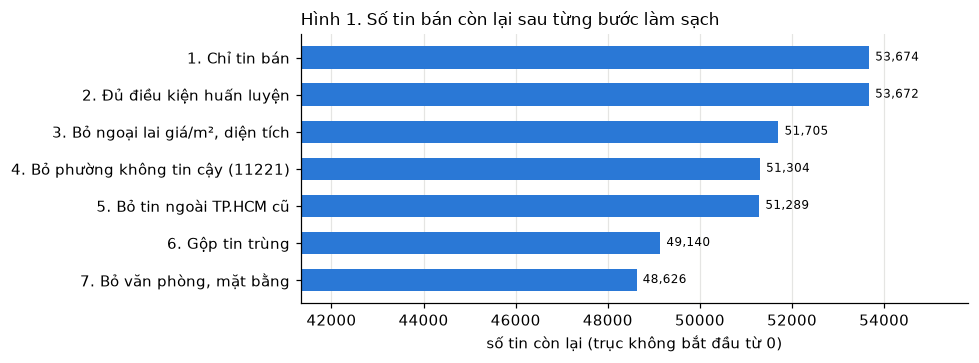

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
f = funnel.iloc[1:]
bars = ax.barh(f.index[::-1], f["còn lại"][::-1], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in f["còn lại"][::-1]], padding=4, fontsize=8)
ax.set_xlim(f["còn lại"].min() * 0.85, f["còn lại"].max() * 1.04)
ax.set_xlabel("số tin còn lại (trục không bắt đầu từ 0)")
ax.set_title("Hình 1. Số tin bán còn lại sau từng bước làm sạch")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Nhận xét.** Từ 163.087 tin (cả thuê lẫn bán) còn 53.674 tin bán; sau làm sạch còn 48.626 tin, tức 90,6% số tin bán được giữ lại.
Hai bước loại nhiều nhất là bỏ ngoại lai (1.967 tin) và gộp tin trùng (2.149 tin, khoảng 4%): cùng một bất động sản được nhiều môi giới đăng,
nếu không gộp thì mô hình sẽ được chấm điểm trên chính những căn nó đã thấy khi học.
Kết quả tái hiện bằng pandas khớp với bảng Gold thật (chênh 2 dòng do Spark tính phân vị xấp xỉ bằng `percentile_approx`).

## 2. Khám phá dữ liệu

Phần này mô tả bảng `gold.ml_price_features` sau làm sạch. Mỗi nhận xét dẫn tới một quyết định tiền xử lý ở mục 3.

### 2.1 Tổng quan theo loại hình

In [4]:
df["posted_date"] = pd.to_datetime(df["posted_date"])
df["district_id"] = df["district_id"].astype("string").astype(object)  # mã là nhãn, không phải số lượng
df["ward_id"] = df["ward_id"].astype("string").astype(object)
df["ppm2_trieu"] = df["price_vnd"] / df["area_m2"] / 1e6

print(f"{len(df):,} tin, {df.shape[1] - 1} cột, đăng từ {df.posted_date.min().date()} đến {df.posted_date.max().date()}")
overview = df.groupby("property_type").agg(
    so_tin=("price_vnd", "size"),
    gia_trung_vi_ty=("price_vnd", lambda x: x.median() / 1e9),
    dien_tich_trung_vi_m2=("area_m2", "median"),
    gia_m2_trung_vi_trieu=("ppm2_trieu", "median"),
    so_loai_con=("property_subtype", "nunique"),
)
overview["ti_le"] = overview["so_tin"] / len(df) * 100
overview.style.format({"so_tin": "{:,.0f}", "gia_trung_vi_ty": "{:.2f}", "dien_tich_trung_vi_m2": "{:.0f}",
                       "gia_m2_trung_vi_trieu": "{:.1f}", "ti_le": "{:.1f}%"})

48,628 tin, 42 cột, đăng từ 2025-07-24 đến 2026-11-16


,so_tin,gia_trung_vi_ty,dien_tich_trung_vi_m2,gia_m2_trung_vi_trieu,so_loai_con,ti_le
property_type,,,,,,
Căn hộ/Chung cư,"7,100",3.58,68,53.8,8,14.6%
Nhà ở,"35,288",5.90,56,110.0,4,72.6%
Đất,"6,240",4.60,110,43.0,4,12.8%


### 2.2 Phân bố giá: vì sao học trên thang log

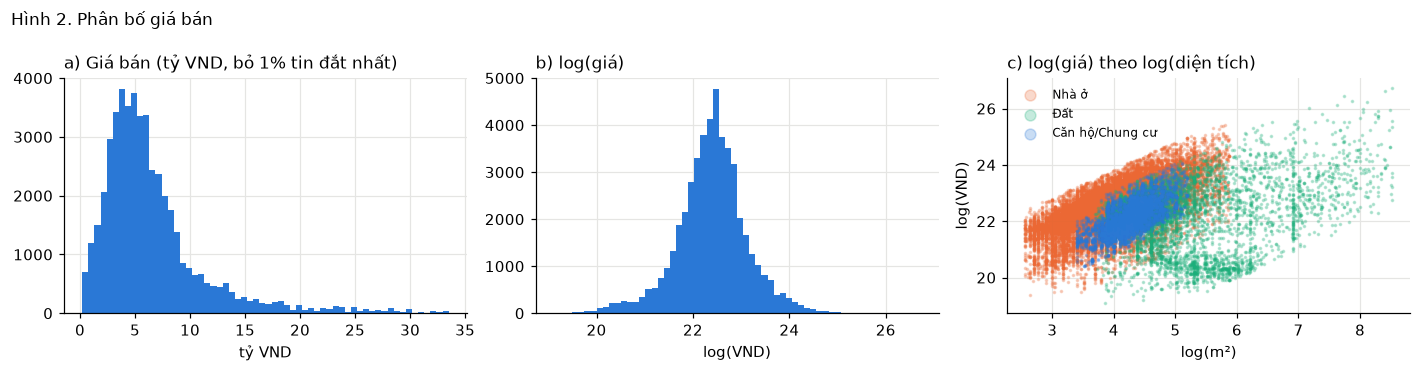

Độ lệch (skewness): giá 12.6 | log(giá) -0.13 | log(giá/m²) -1.77


,"tương quan log(giá), log(m²)",hệ số co giãn giá theo diện tích,độ lệch chuẩn log(giá),độ lệch chuẩn log(giá/m²)
Căn hộ/Chung cư,0.7100,1.1700,0.5100,0.3600
Nhà ở,0.6300,0.7700,0.6800,0.5400
Đất,0.2600,0.2800,1.0300,1.2100


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
price_ty = df["price_vnd"] / 1e9
axes[0].hist(price_ty[price_ty <= price_ty.quantile(0.99)], bins=60, color=BLUE)
axes[0].set_title("a) Giá bán (tỷ VND, bỏ 1% tin đắt nhất)"); axes[0].set_xlabel("tỷ VND")
axes[1].hist(np.log(df["price_vnd"]), bins=60, color=BLUE)
axes[1].set_title("b) log(giá)"); axes[1].set_xlabel("log(VND)")
for t in ["Nhà ở", "Đất", "Căn hộ/Chung cư"]:  # căn hộ vẽ sau cùng để không bị che
    s, c = df[df.property_type == t], TYPE_COLOR[t]
    axes[2].scatter(np.log(s["area_m2"]), np.log(s["price_vnd"]), s=2, alpha=0.25, color=c, label=t)
axes[2].set_title("c) log(giá) theo log(diện tích)"); axes[2].set_xlabel("log(m²)"); axes[2].set_ylabel("log(VND)")
axes[2].legend(frameon=False, fontsize=8, markerscale=5)
fig.suptitle("Hình 2. Phân bố giá bán", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

print(f"Độ lệch (skewness): giá {df.price_vnd.skew():.1f} | log(giá) {np.log(df.price_vnd).skew():.2f} | "
      f"log(giá/m²) {np.log(df.price_vnd / df.area_m2).skew():.2f}")
elasticity = pd.DataFrame({
    t: {"tương quan log(giá), log(m²)": np.corrcoef(np.log(g.area_m2), np.log(g.price_vnd))[0, 1],
        "hệ số co giãn giá theo diện tích": np.polyfit(np.log(g.area_m2), np.log(g.price_vnd), 1)[0],
        "độ lệch chuẩn log(giá)": np.log(g.price_vnd).std(),
        "độ lệch chuẩn log(giá/m²)": np.log(g.price_vnd / g.area_m2).std()}
    for t, g in df.groupby("property_type")}).T[["tương quan log(giá), log(m²)", "hệ số co giãn giá theo diện tích",
                                                "độ lệch chuẩn log(giá)", "độ lệch chuẩn log(giá/m²)"]]
elasticity.round(2)

**Nhận xét.**
- Giá lệch phải rất mạnh (độ lệch 12,6): phần lớn tin dưới 10 tỷ nhưng đuôi kéo tới hàng trăm tỷ. Lấy log đưa phân phối về gần đối xứng (độ lệch −0,13),
  nên mô hình được huấn luyện trên **log(giá)** để vài căn rất đắt không chi phối hàm mất mát.
- Quan hệ giữa giá và diện tích khác nhau theo loại hình (Hình 2c, bảng trên): căn hộ và nhà ở có giá tăng gần tỉ lệ với diện tích,
  còn đất thì không, vì lô đất lớn thường là đất nông nghiệp hoặc chỉ một phần là thổ cư nên giá/m² thấp.
  Đây là cơ sở cho việc chọn biến mục tiêu ở mục 3.4.

### 2.3 Giá/m² theo loại hình và vị trí

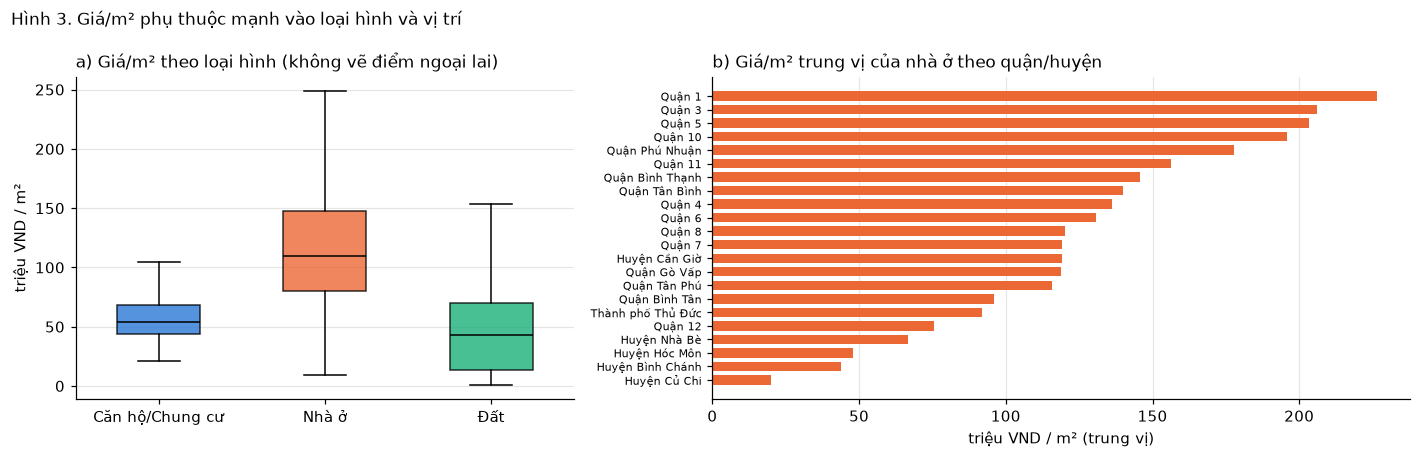

Nhà ở: quận đắt nhất gấp 11 lần quận rẻ nhất (Quận 1 226 so với Huyện Củ Chi 20 triệu/m²)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
types = list(TYPE_COLOR)
box = axes[0].boxplot([df.loc[df.property_type == t, "ppm2_trieu"] for t in types], tick_labels=types,
                      showfliers=False, patch_artist=True, widths=0.5, medianprops={"color": "black"})
for patch, t in zip(box["boxes"], types):
    patch.set_facecolor(TYPE_COLOR[t]); patch.set_alpha(0.8)
axes[0].set_ylabel("triệu VND / m²"); axes[0].set_title("a) Giá/m² theo loại hình (không vẽ điểm ngoại lai)")
axes[0].grid(axis="x", visible=False)

house = df[df.property_type == "Nhà ở"]
by_district = house.groupby("district")["ppm2_trieu"].median().sort_values()
axes[1].barh(by_district.index, by_district.values, color=ORANGE, height=0.7)
axes[1].tick_params(axis="y", labelsize=7); axes[1].set_xlabel("triệu VND / m² (trung vị)")
axes[1].set_title("b) Giá/m² trung vị của nhà ở theo quận/huyện"); axes[1].grid(axis="y", visible=False)
fig.suptitle("Hình 3. Giá/m² phụ thuộc mạnh vào loại hình và vị trí", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
print(f"Nhà ở: quận đắt nhất gấp {by_district.iloc[-1] / by_district.iloc[0]:.0f} lần quận rẻ nhất "
      f"({by_district.index[-1]} {by_district.iloc[-1]:.0f} so với {by_district.index[0]} {by_district.iloc[0]:.0f} triệu/m²)")

**Nhận xét.** Giá/m² trung vị của nhà ở (110 triệu) gấp đôi căn hộ (54 triệu) và đất (43 triệu); đất phân tán rộng nhất.
Trong cùng loại nhà ở, quận đắt nhất gấp 11 lần quận rẻ nhất. Vị trí vì vậy là yếu tố quyết định giá, nên ngoài mã quận, phường
cần thêm đặc trưng mô tả trực tiếp **mức giá của khu vực** (mục 3.3).

### 2.4 Dữ liệu thiếu

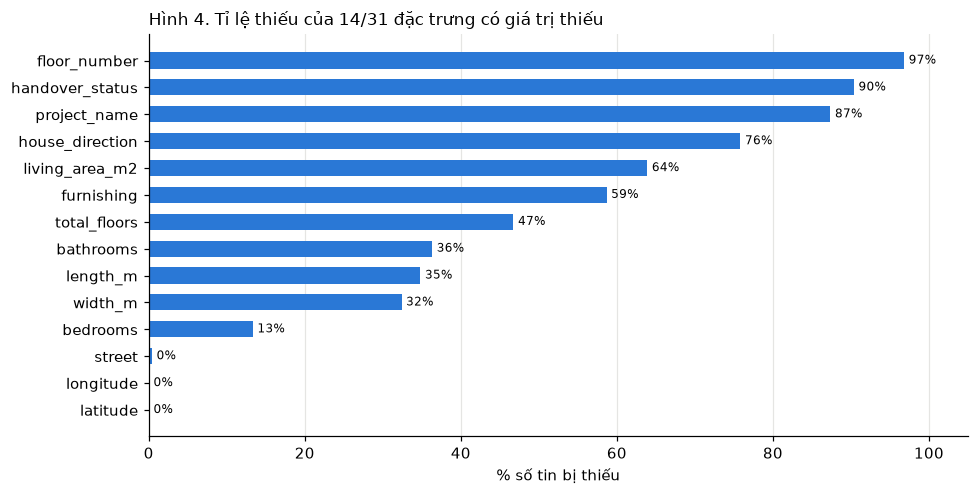

Tỉ lệ thiếu (%) theo loại hình:


property_type,Căn hộ/Chung cư,Nhà ở,Đất,Tất cả
latitude,0.1000,0.0000,0.0000,0.0000
longitude,0.1000,0.0000,0.0000,0.0000
street,0.8000,0.4000,0.3000,0.4000
bedrooms,0.2000,0.7000,100.0000,13.3000
width_m,100.0000,22.0000,14.3000,32.4000
length_m,100.0000,24.6000,18.3000,34.8000
bathrooms,16.8000,29.0000,100.0000,36.3000
total_floors,100.0000,26.6000,100.0000,46.8000
furnishing,37.7000,55.6000,100.0000,58.7000
living_area_m2,100.0000,50.3000,100.0000,63.9000


In [7]:
NUMERIC = ["area_m2", "living_area_m2", "width_m", "length_m", "bedrooms", "bathrooms",
           "total_floors", "floor_number", "latitude", "longitude"]
BOOLEAN = ["is_in_project", "has_car_alley", "is_frontage", "is_wide_back", "is_narrow_back",
           "is_dilapidated", "is_not_completed", "is_planning_affected", "has_certificate"]
LOW_CARD = ["district_id", "area_zone", "district_type", "property_type", "property_subtype",
            "house_direction", "furnishing", "handover_status", "legal_category"]
HIGH_CARD = ["ward_id", "street", "project_name"]
CATEGORICAL = LOW_CARD + HIGH_CARD
FEATURES = NUMERIC + BOOLEAN + CATEGORICAL

missing = (df[FEATURES].isna().groupby(df["property_type"]).mean().T * 100)
missing["Tất cả"] = df[FEATURES].isna().mean() * 100
missing = missing[missing["Tất cả"] > 0].sort_values("Tất cả")

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(missing.index, missing["Tất cả"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in missing["Tất cả"]], padding=3, fontsize=8)
ax.set_xlim(0, 105); ax.set_xlabel("% số tin bị thiếu"); ax.grid(axis="y", visible=False)
ax.set_title(f"Hình 4. Tỉ lệ thiếu của {len(missing)}/{len(FEATURES)} đặc trưng có giá trị thiếu")
plt.tight_layout(); plt.show()
print("Tỉ lệ thiếu (%) theo loại hình:")
missing[types + ["Tất cả"]].round(1)

**Nhận xét.** Phần lớn giá trị thiếu là **thiếu theo cấu trúc**, không phải thiếu ngẫu nhiên: đất không có phòng ngủ, số tầng;
căn hộ không có chiều ngang, chiều dài; nhà ở không có "tầng số mấy". Chỉ một số cột thiếu thật sự do người đăng bỏ trống
(hướng nhà 76%, nội thất 59%). Do đó:
- **Không điền giá trị thay thế** (trung bình, trung vị): điền sẽ tạo ra thông tin sai, ví dụ một lô đất "có 2 phòng ngủ".
  Cột số giữ NaN, cột phân loại nhận nhãn riêng `__missing__`. XGBoost học được hướng rẽ riêng cho giá trị thiếu ở mỗi nút,
  nên "không có thông tin" cũng trở thành một tín hiệu.
- **Không bỏ cột vì thiếu nhiều**: cột thiếu 90% trên toàn bộ vẫn có ích cho nhóm có nó (ví dụ `handover_status` chỉ có ở căn hộ,
  `floor_number` chỉ có ở căn hộ).

### 2.5 Số mức của biến phân loại

In [8]:
card = pd.DataFrame({"so_muc": df[CATEGORICAL].nunique(),
                     "muc_pho_bien_nhat": df[CATEGORICAL].apply(lambda s: s.value_counts().index[0] if s.notna().any() else None),
                     "ti_le_thieu_%": df[CATEGORICAL].isna().mean() * 100})
card["nhom"] = np.where(card.index.isin(HIGH_CARD), "nhiều mức", "ít mức")
card.sort_values("so_muc")

,so_muc,muc_pho_bien_nhat,ti_le_thieu_%,nhom
area_zone,2,Nội thành,0.0000,ít mức
handover_status,2,Đã bàn giao,90.3821,ít mức
property_type,3,Nhà ở,0.0000,ít mức
district_type,3,Quận,0.0000,ít mức
furnishing,4,Nội thất đầy đủ,58.6822,ít mức
legal_category,5,Có sổ,0.0000,ít mức
house_direction,8,Đông Nam,75.8370,ít mức
property_subtype,16,"Nhà ngõ, hẻm",0.0000,ít mức
district_id,22,13119,0.0000,ít mức
ward_id,315,9459,0.0000,nhiều mức


**Nhận xét.** 9 cột có tối đa 22 mức nên mã hoá thứ tự là đủ. Ba cột còn lại có nhiều mức: 315 phường, 789 dự án, 6.677 tên đường.
Mã hoá one-hot sẽ sinh ra hơn 7.700 cột thưa, phần lớn chỉ có vài tin, nên ba cột này được **mã hoá mục tiêu** (mục 3.3).

### 2.6 Số tin theo thời gian

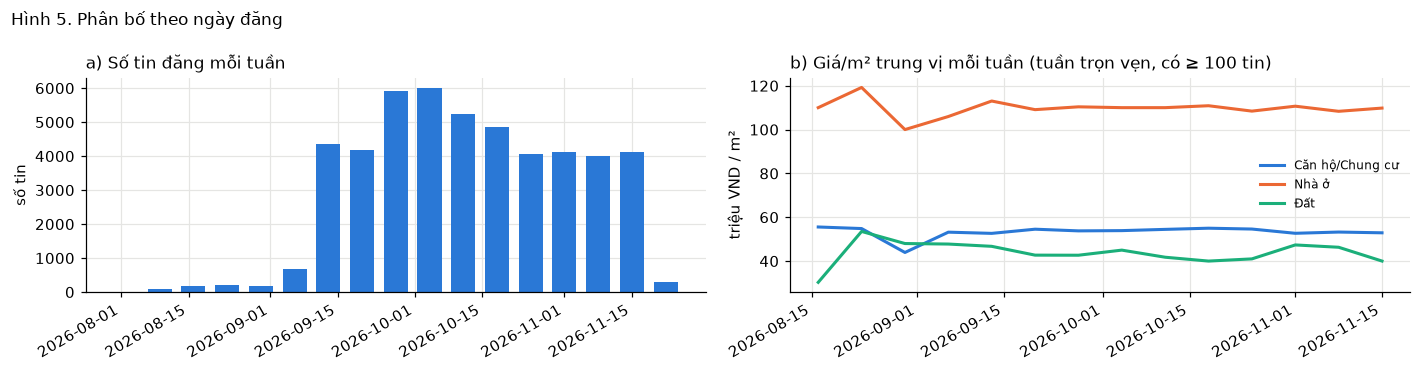

84% số tin được đăng trong 60 ngày gần nhất (hệ thống thu thập từ giữa tháng 9/2026; tin cũ hơn là tin vẫn còn hiển thị lúc thu thập).


In [9]:
recent_df = df[df.posted_date >= "2026-08-01"]  # trước đó chỉ lác đác vài tin cũ còn hiển thị
weekly = recent_df.set_index("posted_date").resample("W")["price_vnd"].size()
ppm2_week = recent_df.set_index("posted_date").groupby("property_type").resample("W")["ppm2_trieu"].median().unstack(0)
full_weeks = weekly.index[weekly.index <= df.posted_date.max()]  # bỏ tuần cuối chưa trọn
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].bar(weekly.index, weekly.values, width=5, color=BLUE)
axes[0].set_title("a) Số tin đăng mỗi tuần"); axes[0].set_ylabel("số tin")
recent = ppm2_week.loc[weekly[weekly >= 100].index.min():full_weeks.max()]
for t in types:
    axes[1].plot(recent.index, recent[t], color=TYPE_COLOR[t], lw=2, label=t)
axes[1].set_title("b) Giá/m² trung vị mỗi tuần (tuần trọn vẹn, có ≥ 100 tin)"); axes[1].set_ylabel("triệu VND / m²")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Hình 5. Phân bố theo ngày đăng", x=0.01, ha="left", fontsize=11)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
share = (df.posted_date >= df.posted_date.max() - pd.Timedelta(days=60)).mean()
print(f"{share:.0%} số tin được đăng trong 60 ngày gần nhất (hệ thống thu thập từ giữa tháng 9/2026; "
      f"tin cũ hơn là tin vẫn còn hiển thị lúc thu thập).")

**Nhận xét.** Hệ thống bắt đầu thu thập từ đầu tháng 9/2026; 84% số tin được đăng trong 60 ngày gần nhất,
các tin cũ hơn là tin vẫn còn hiển thị tại thời điểm thu thập. Giá/m² trung vị theo tuần ổn định (nhà ở quanh 110, căn hộ quanh 54 triệu/m²),
tức không có xu hướng giá rõ trong khoảng thời gian này, nên mô hình không dùng đặc trưng thời gian.
Tuy vậy, cách đánh giá vẫn phải theo thời gian (mục 4), vì đó là cách mô hình được dùng thật.

## 3. Tiền xử lý và xây dựng đặc trưng

### 3.1 Chọn đặc trưng

Nguyên tắc: **chỉ dùng thông tin người dùng có thể nhập khi hỏi giá** một căn nhà. Như vậy mô hình dùng được ngay trên form
dự đoán của API, và không có đặc trưng nào "nhìn trộm" kết quả.

| Nhóm | Cột | Số cột | Xử lý |
|---|---|---|---|
| Số | diện tích, diện tích sử dụng, ngang, dài, phòng ngủ, phòng tắm, số tầng, tầng, vĩ độ, kinh độ | 10 | Giữ nguyên; giá trị thiếu để NaN (XGBoost tự học hướng rẽ cho NaN) |
| Đúng/sai | trong dự án, hẻm xe hơi, mặt tiền, nở hậu, tóp hậu, nhà nát, chưa hoàn công, dính quy hoạch, có sổ | 9 | True/False → 1/0, thiếu → NaN |
| Phân loại ít mức | quận, khu vực, loại quận, loại hình, loại con, hướng, nội thất, bàn giao, pháp lý | 9 | Mã hoá thứ tự (OrdinalEncoder); thiếu → nhãn `__missing__` |
| Phân loại nhiều mức | phường, đường, dự án | 3 | Mã hoá mục tiêu chéo (TargetEncoder, 5 fold) |
| Giá khu vực | giá/m² trung bình của (phường × loại hình), (quận × đường × loại hình), (dự án), (quận × loại con) và số tin của mỗi nhóm | 8 | AreaPriceEncoder, tính ngoài fold (mục 3.3) |

**Các cột bị loại có chủ đích:**

| Cột | Lý do loại |
|---|---|
| `price_per_m2`, `log_price_vnd` | Suy ra trực tiếp từ giá, dùng là rò rỉ mục tiêu |
| `district`, `ward` (tên) | Trùng thông tin với `district_id`, `ward_id` |
| `is_broker`, `duplicate_count`, `observed_date` | Đặc điểm của tin đăng, không phải của bất động sản; người dùng không biết khi hỏi giá |
| `posted_date` | Chỉ dùng để chia train/test theo thời gian |
| `property_category` | Trùng với `property_type` |

### 3.2 Chuẩn hoá kiểu dữ liệu

Hàm `prepare` là "hợp đồng" chung giữa pipeline huấn luyện và API: mọi đầu vào đều được đưa về đúng kiểu trước khi vào mô hình.
Bảng dưới so sánh cùng vài tin trước và sau khi chuẩn hoá.

In [10]:
MISSING = "__missing__"


def prepare(frame):
    out = frame.copy()
    for c in NUMERIC:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype("float64")
    for c in BOOLEAN:
        out[c] = out[c].map({True: 1.0, False: 0.0}).astype("float64")
    for c in CATEGORICAL:
        out[c] = out[c].astype("object").where(out[c].notna(), MISSING).astype(str)
    return out[FEATURES]


show = ["has_car_alley", "has_certificate", "house_direction", "furnishing", "project_name", "bedrooms"]
sample = df[df.property_type == "Nhà ở"].sample(4, random_state=3)
pd.concat({"trước": sample[show].astype(object), "sau": prepare(sample)[show].astype(object)}, axis=1)

trước                                                     \
      has_car_alley has_certificate house_direction         furnishing   
40582          True            True            Đông    Nội thất đầy đủ   
33180          True            True            None  Hoàn thiện cơ bản   
12169         False           False            None               None   
41529          True           False         Tây Nam    Nội thất đầy đủ   

                                      sau                                  \
      project_name bedrooms has_car_alley has_certificate house_direction   
40582         None   4.0000        1.0000          1.0000            Đông   
33180         None   2.0000        1.0000          1.0000     __missing__   
12169         None   2.0000        0.0000          0.0000     __missing__   
41529         None   2.0000        1.0000          0.0000         Tây Nam   

                                                
              furnishing project_name bedrooms  
40582    Nội thất đầy đủ  __missing__   4.0000  
33180  Hoàn thiện cơ bản  __missing__   2.0000  
12169        __missing__  __missing__   2.0000  
41529    Nội thất đầy đủ  __missing__   2.0000

### 3.3 Mã hoá biến phân loại và đặc trưng giá khu vực

- **Biến ít mức** được mã hoá thứ tự: mỗi nhãn thành một số nguyên. Với mô hình cây, thứ tự này không mang nghĩa lớn bé,
  cây chỉ dùng nó để tách nhóm. Nhãn chưa gặp khi dự đoán thành NaN.
- **Biến nhiều mức** (hàng nghìn phường, đường) không thể mã hoá thứ tự hiệu quả. Mã hoá mục tiêu thay mỗi nhãn bằng
  trung bình biến mục tiêu của nhãn đó, có làm trơn về trung bình chung khi nhãn ít tin.
  Khi huấn luyện, dữ liệu được chia 5 fold và mỗi tin được mã hoá bằng 4 fold còn lại (*cross-fitting*),
  nên giá của chính tin đó không lọt vào đặc trưng của nó.
- **Đặc trưng giá khu vực** (`AreaPriceEncoder`, viết riêng cho bài toán): với mỗi nhóm khu vực $g$ (ví dụ phường × loại hình),
  giá/m² trung bình được làm trơn về giá trung bình của loại hình:

  $$\text{ppm2}_g = \frac{\sum_{i \in g} y_i + m \cdot \bar y_{\text{loại hình}}}{n_g + m}, \qquad m = 5$$

  với $y_i = \log(\text{giá}_i / \text{diện tích}_i)$. Nhóm có ít tin thì dựa nhiều hơn vào trung bình loại hình.
  Cũng tính ngoài fold như trên. Số tin $n_g$ của nhóm được đưa vào làm đặc trưng để mô hình biết giá trị trung bình đáng tin tới đâu.

Ô dưới fit bộ tiền xử lý trên toàn tập dữ liệu chỉ để minh hoạ đầu ra; khi huấn luyện thật, nó chỉ được fit trên tập train.

In [11]:
def build_preprocessor():
    return ColumnTransformer([
        ("num", "passthrough", NUMERIC + BOOLEAN),
        ("low", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               dtype=np.float64), LOW_CARD),
        ("high", make_pipeline(SimpleImputer(strategy="constant", fill_value=MISSING),
                               TargetEncoder(target_type="continuous", random_state=42)), HIGH_CARD),
        ("area", AreaPriceEncoder(), AREA_COLUMNS),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


demo_y = np.log(df["price_vnd"] / df["area_m2"])
demo = build_preprocessor().fit_transform(prepare(df), demo_y)
print(f"Ma trận đặc trưng: {demo.shape[0]:,} dòng × {demo.shape[1]} cột "
      f"({len(NUMERIC)} số + {len(BOOLEAN)} đúng/sai + {len(LOW_CARD)} ít mức + {len(HIGH_CARD)} nhiều mức "
      f"+ {2 * len(AREA_GROUPS)} giá khu vực)")
cols = ["ward_id", "street", "district_id", "property_subtype"] + [f"ppm2_{g}" for g in AREA_GROUPS] + ["n_ward_type"]
example = pd.concat([df.loc[sample.index, ["ward", "street", "property_subtype"]],
                     demo.loc[sample.index, cols]], axis=1)
example

Ma trận đặc trưng: 48,628 dòng × 39 cột (10 số + 9 đúng/sai + 9 ít mức + 3 nhiều mức + 8 giá khu vực)


,ward,street,property_subtype,ward_id,street,district_id,property_subtype,ppm2_ward_type,ppm2_street_type,ppm2_project,ppm2_district_subtype,n_ward_type
40582,Phường Bình Hưng Hòa,Đường Cây Cám,"Nhà ngõ, hẻm",18.2771,17.6923,10.0000,6.0000,18.3194,18.3619,NaN,18.3029,548.0000
33180,Phường Bình Hưng Hoà B,Đường Liên khu 5-6,"Nhà ngõ, hẻm",18.0656,18.1749,10.0000,6.0000,18.1385,18.2566,NaN,18.3051,373.0000
12169,Phường Tân Thới Hòa,Đường Lũy Bán Bích,"Nhà ngõ, hẻm",18.3773,18.5301,15.0000,6.0000,18.5666,18.5300,NaN,18.5257,100.0000
41529,Phường 14,Hẻm 331 Phan Huy Ích,"Nhà ngõ, hẻm",18.4609,18.2115,12.0000,6.0000,18.5388,NaN,NaN,18.5507,411.0000


In [12]:
area_cols = [f"ppm2_{g}" for g in AREA_GROUPS]
corr = demo[area_cols].corrwith(demo_y).rename("tương quan với log(giá/m²)")
coverage = demo[area_cols].notna().mean().rename("tỉ lệ tin có giá trị")
pd.concat([corr, coverage], axis=1).style.format("{:.2f}")

,tương quan với log(giá/m²),tỉ lệ tin có giá trị
ppm2_ward_type,0.87,1.00
ppm2_street_type,0.84,0.88
ppm2_project,0.83,0.12
ppm2_district_subtype,0.88,1.00


**Nhận xét.** Cả bốn đặc trưng giá khu vực tương quan 0,83–0,88 với biến mục tiêu. Giá theo phường và theo quận × loại con có ở mọi tin;
giá theo đường có ở 88% tin (đường chỉ có một tin thì khi tính ngoài fold không còn tin nào khác để lấy trung bình); giá theo dự án
chỉ có ở 12% tin, chủ yếu là căn hộ. Mục 10 cho thấy đây là nhóm đặc trưng mô hình dựa vào nhiều nhất.

### 3.4 Biến mục tiêu: log(giá/m²)

Mô hình không học trực tiếp giá, mà học $\log(\text{giá}/\text{m}^2) = \log(\text{giá}) - \log(\text{diện tích})$,
rồi cộng lại $\log(\text{diện tích})$ khi dự đoán (lớp `PricePerM2Regressor`). Hai lý do:

1. **Thang log** (mục 2.2): giá lệch phải rất mạnh, log đưa về gần đối xứng. Thêm nữa, trên thang log sai số tương đối
   thành sai số tuyệt đối: lệch 10% ở căn 2 tỷ và căn 20 tỷ được phạt như nhau, khớp với chỉ số MAPE dùng để đánh giá.
2. **Chia cho diện tích**: với căn hộ (hệ số co giãn 1,17) và nhà ở (0,77), giá tăng gần tỉ lệ với diện tích, nên giá/m²
   tách phần "to hay nhỏ" khỏi phần "đắt hay rẻ" và có độ phân tán nhỏ hơn hẳn log(giá) (0,36 so với 0,51; 0,54 so với 0,68).
   Hai loại này chiếm 87% dữ liệu. Với đất thì ngược lại (hệ số 0,28: lô càng lớn càng rẻ/m²),
   nhưng `area_m2` vẫn là một đặc trưng đầu vào nên cây vẫn học được quan hệ này.

Lựa chọn này đã được kiểm chứng bằng thực nghiệm trong `price_model_improvements.ipynb`: học log(giá/m²) thay vì log(giá)
giảm MAPE test từ 20,21% xuống 19,97% (trung bình 3 seed).

Đầu ra của mô hình vẫn là $\log(\text{giá})$, nên API và cổng chất lượng chỉ cần lấy $e^{\hat y}$.

## 4. Chia dữ liệu theo thời gian

Mô hình được dùng để định giá tin **mới đăng**, nên phải được đánh giá trên tin mới hơn mọi tin nó đã học.
Chia ngẫu nhiên sẽ cho mô hình thấy các tin cùng thời điểm (thường là cùng dự án, cùng đợt mở bán) ở cả hai phía
và cho kết quả lạc quan hơn thực tế.

- **Tập kiểm tra (test)**: 20% tin mới nhất theo ngày đăng, cắt ở trọn ngày. Chỉ dùng một lần ở mục 8 để chấm điểm cuối.
- **Tập kiểm định (valid)**: 20% tin mới nhất của phần còn lại. Dùng để dò siêu tham số ở mục 7.
- **Tập huấn luyện (train_fit)**: phần cũ nhất. Khi chấm trên test, mô hình được fit lại trên train = train_fit + valid.

Đây đúng là cách pipeline chia dữ liệu (`--test-fraction 0.2`, `--tune-valid-fraction 0.2`).

,số tin,từ ngày,đến ngày,Nhà ở,Căn hộ/Chung cư,Đất
train_fit,31604,2025-07-24,2026-10-17,71.0000,15.3000,13.8000
valid,7775,2026-10-18,2026-10-30,75.2000,13.5000,11.3000
test,9249,2026-10-31,2026-11-16,75.8000,13.3000,10.9000


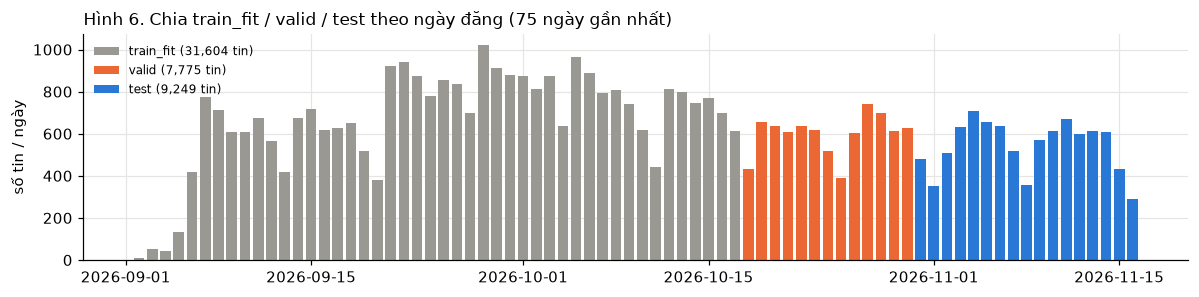

In [13]:
def split_newest(frame, fraction):
    cutoff = frame["posted_date"].quantile(1 - fraction).normalize()
    newest = frame["posted_date"] > cutoff
    return frame[~newest], frame[newest]


train, test = split_newest(df, 0.20)
train_fit, valid = split_newest(train, 0.20)
parts = {"train_fit": train_fit, "valid": valid, "test": test}
split_table = pd.DataFrame({
    name: {"số tin": len(p), "từ ngày": p.posted_date.min().date(), "đến ngày": p.posted_date.max().date(),
           **(p.property_type.value_counts(normalize=True) * 100).round(1).to_dict()}
    for name, p in parts.items()}).T
display(split_table)

fig, ax = plt.subplots(figsize=(11, 2.8))
daily = df.groupby("posted_date").size()
start = daily.index[daily.index >= df.posted_date.max() - pd.Timedelta(days=75)].min()
for (name, p), color in zip(parts.items(), [GRAY, ORANGE, BLUE]):
    d = p.groupby("posted_date").size()
    d = d[d.index >= start]
    ax.bar(d.index, d.values, width=0.8, color=color, label=f"{name} ({len(p):,} tin)")
ax.set_ylabel("số tin / ngày"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Hình 6. Chia train_fit / valid / test theo ngày đăng (75 ngày gần nhất)")
plt.tight_layout(); plt.show()

## 5. Mô hình cơ sở và cấu hình ban đầu

**Mô hình cơ sở** (cũng là mốc của cổng chất lượng): giá dự đoán = giá/m² trung vị của (quận × loại hình) trên tập train × diện tích.
Mô hình học máy chỉ có ý nghĩa khi tốt hơn rõ rệt so với cách định giá "theo mặt bằng chung" này.

**Mô hình XGBoost** (gradient boosting trên cây quyết định) được chọn sau khi so sánh với HistGradientBoosting và CatBoost
(notebook `price_model_comparison.ipynb`). Cấu hình ban đầu dùng siêu tham số đặt tay.

In [14]:
CURRENT_PARAMS = dict(n_estimators=800, learning_rate=0.05, max_depth=7, min_child_weight=5,
                      subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0)


def build_model(params, seed=42):
    return PricePerM2Regressor(Pipeline([
        ("prep", build_preprocessor()),
        ("model", XGBRegressor(**params, tree_method="hist", n_jobs=-1, random_state=seed)),
    ]))


def fit_predict(fit, score, params, seed=42):
    # Học log(giá) trên `fit`, trả về giá VND dự đoán cho `score`.
    model = build_model(params, seed).fit(prepare(fit), np.log(fit["price_vnd"]))
    return np.exp(model.predict(prepare(score)))


def baseline_predict(fit, score):
    ppm2 = fit["price_vnd"] / fit["area_m2"]
    by_segment = ppm2.groupby([fit["district_id"], fit["property_type"]]).median()
    rate = pd.Series(by_segment.reindex(pd.MultiIndex.from_frame(score[["district_id", "property_type"]])).to_numpy(),
                     index=score.index)
    rate = rate.fillna(score["property_type"].map(ppm2.groupby(fit["property_type"]).median())).fillna(ppm2.median())
    return (rate * score["area_m2"]).to_numpy()


def mape(pred, frame):
    return float((np.abs(pred - frame["price_vnd"]) / frame["price_vnd"]).mean())


def scores(pred, frame):
    ape = np.abs(pred - frame["price_vnd"].to_numpy()) / frame["price_vnd"].to_numpy()
    return {"MAPE": ape.mean(), "MdAPE": np.median(ape), "sai ≤ 20%": (ape <= 0.20).mean()}


t0 = time.time()
first = pd.DataFrame({
    "Cơ sở: trung vị giá/m² (quận × loại hình)": scores(baseline_predict(train, test), test),
    "XGBoost, siêu tham số đặt tay": scores(fit_predict(train, test, CURRENT_PARAMS), test),
}).T
print(f"Fit trên {len(train):,} tin train, chấm trên {len(test):,} tin test ({time.time() - t0:.0f}s)")
first.style.format("{:.2%}")

Fit trên 39,379 tin train, chấm trên 9,249 tin test (3s)


,MAPE,MdAPE,sai ≤ 20%
Cơ sở: trung vị giá/m² (quận × loại hình),35.01%,22.48%,45.63%
"XGBoost, siêu tham số đặt tay",19.54%,13.26%,67.17%


**Nhận xét.** Mô hình cơ sở sai trung bình 35%, chỉ 46% tin được định giá trong ±20%. XGBoost với siêu tham số đặt tay giảm MAPE xuống 19,5%
(giảm 44% sai số) và đưa tỉ lệ tin sai ≤ 20% lên 67%. Các mục sau tìm cách cải thiện thêm từ cấu hình này.

## 6. Lọc nhiễu tập huấn luyện

Bước lọc ngoại lai ở dbt (mục 1) dùng ngưỡng chung cho cả thành phố, nên vẫn có thể sót những tin giá/m² hợp lý
ở mức thành phố nhưng bất thường **trong khu vực của nó** (ví dụ nhà hẻm Quận 8 giá 375 triệu/m²).
Thử nghiệm thêm một bước lọc cục bộ, chỉ áp dụng cho tập train (tập test giữ nguyên để điểm số trung thực):

Trong mỗi nhóm (quận × loại con), tính trung vị $\tilde y$ của $\log(\text{giá/m}^2)$ và độ lệch tuyệt đối trung vị
$\text{MAD} = 1.4826 \cdot \text{median}(|y - \tilde y|)$ (hệ số 1.4826 để MAD tương đương độ lệch chuẩn khi phân phối chuẩn).
Bỏ tin có $|y - \tilde y| > k \cdot \text{MAD}$, với $k = 5$ (rất lỏng, chỉ bắt lỗi rõ ràng).

In [15]:
def noise_mask(frame, k):
    y = np.log(frame["price_vnd"] / frame["area_m2"])
    groups = [frame["district_id"], frame["property_subtype"]]
    median = y.groupby(groups).transform("median")
    mad = (y - median).abs().groupby(groups).transform("median") * 1.4826
    return (y - median).abs() / mad.clip(lower=0.05) <= k


NOISE_K = 5
keep = noise_mask(train, NOISE_K)
train_filtered = train[keep]
print(f"Bỏ {(~keep).sum():,} / {len(train):,} tin train ({(~keep).mean():.2%}). Ví dụ:")
train.loc[~keep, ["district", "property_subtype", "area_m2", "price_vnd", "ppm2_trieu"]].sample(
    min(8, (~keep).sum()), random_state=1).sort_values("ppm2_trieu")

Bỏ 35 / 39,379 tin train (0.09%). Ví dụ:


,district,property_subtype,area_m2,price_vnd,ppm2_trieu
31875,Quận Tân Phú,Đất thổ cư,50.0000,300000000,6.0000
27730,Thành phố Thủ Đức,"Nhà ngõ, hẻm",160.0000,1699000000,10.6188
38686,Quận 8,"Nhà ngõ, hẻm",40.0000,680000000,17.0000
39435,Quận 7,"Nhà mặt phố, mặt tiền",75.0000,1500000000,20.0000
2279,Quận 8,"Nhà ngõ, hẻm",35.0000,750000000,21.4286
37706,Quận 10,"Nhà ngõ, hẻm",22.0000,950000000,43.1818
45753,Quận 12,Nhà phố liền kề,14.0000,5250000000,375.0000
32088,Huyện Hóc Môn,"Nhà mặt phố, mặt tiền",20.0000,7500000000,375.0000


## 7. Dò siêu tham số bằng Optuna

Mỗi lần thử: fit trên `train_fit`, chấm MAPE trên `valid`. Tập test **không** tham gia, nên kết quả ở mục 8 không bị lạc quan.
Thuật toán lấy mẫu TPE (*Tree-structured Parzen Estimator*): sau vài lần thử ngẫu nhiên, nó mô hình hoá vùng tham số cho kết quả tốt
và tập trung lấy mẫu ở đó.

Dò hai bước:

- **7.1 Dò rộng**: 150 lần thử trên không gian rộng (bảng dưới). Lần thử 0 là cấu hình đặt tay, làm mốc so sánh.
- **7.2 Dò hẹp**: 40 lần thử trong vùng [min, max] mà 15 lần thử tốt nhất của bước dò rộng rơi vào.
  Lần thử đầu là bộ tốt nhất của bước dò rộng, nên kết quả không thể kém hơn.

| Siêu tham số | Ý nghĩa | Vùng dò rộng |
|---|---|---|
| `n_estimators` | số cây | 400 – 2000 |
| `learning_rate` | mức đóng góp của mỗi cây | 0.01 – 0.1 (thang log) |
| `max_depth` | độ sâu tối đa của cây | 4 – 10 |
| `min_child_weight` | tổng trọng số tối thiểu ở một lá (chống học vẹt nhóm nhỏ) | 1 – 20 |
| `subsample` | tỉ lệ dòng lấy ngẫu nhiên cho mỗi cây | 0.6 – 1.0 |
| `colsample_bytree` | tỉ lệ cột lấy ngẫu nhiên cho mỗi cây | 0.4 – 1.0 |
| `reg_lambda`, `reg_alpha` | phạt L2, L1 trên trọng số lá | 0.1 – 10, 0.001 – 5 (thang log) |
| `gamma` | mức giảm lỗi tối thiểu để tách nút | 0.001 – 1 (thang log) |

In [16]:
WIDE_CSV, NARROW_CSV = "optuna_wide_search.csv", "optuna_narrow_search.csv"
WIDE_TRIALS, NARROW_TRIALS, TOP_K = 150, 40, 15
WIDE_SPACE = {  # tên: (thấp, cao, thang log?, bước)
    "n_estimators":     (400, 2000, False, 100),
    "learning_rate":    (0.01, 0.1, True, None),
    "max_depth":        (4, 10, False, 1),
    "min_child_weight": (1, 20, False, 1),
    "subsample":        (0.6, 1.0, False, None),
    "colsample_bytree": (0.4, 1.0, False, None),
    "reg_lambda":       (0.1, 10.0, True, None),
    "reg_alpha":        (1e-3, 5.0, True, None),
    "gamma":            (1e-3, 1.0, True, None),
}
INT_PARAMS = {"n_estimators", "max_depth", "min_child_weight"}


def distributions(space):
    return {n: (optuna.distributions.IntDistribution(int(lo), int(hi), step=step or 1) if n in INT_PARAMS
                else optuna.distributions.FloatDistribution(lo, hi, log=log))
            for n, (lo, hi, log, step) in space.items()}


def run_search(space, n_trials, first_params, name):
    def objective(trial):
        params = {n: (trial.suggest_int(n, int(lo), int(hi), step=step or 1) if n in INT_PARAMS
                      else trial.suggest_float(n, lo, hi, log=log))
                  for n, (lo, hi, log, step) in space.items()}
        return mape(fit_predict(train_fit, valid, params), valid)

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42), study_name=name)
    study.enqueue_trial(first_params)
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials)
    print(f"{name}: {n_trials} lần thử trong {(time.time() - t0) / 60:.0f} phút")
    return study


def load_or_run(path, space, n_trials, first_params, name):
    # Đọc lại kết quả đã lưu nếu có; không thì dò và lưu ra CSV.
    if not os.path.exists(path):
        study = run_search(space, n_trials, first_params, name)
        rows = [{"trial": t.number, "valid_mape": t.value, **t.params} for t in study.trials]
        pd.DataFrame(rows).to_csv(path, index=False)
    trials = pd.read_csv(path).set_index("trial")
    study = optuna.create_study(direction="minimize", study_name=name)
    for _, r in trials.iterrows():
        params = {n: int(r[n]) if n in INT_PARAMS else float(r[n]) for n in space}
        study.add_trial(optuna.trial.create_trial(params=params, distributions=distributions(space),
                                                  value=float(r["valid_mape"])))
    print(f"{name}: {len(trials)} lần thử (từ {path}), tốt nhất {study.best_value:.2%} ở lần {study.best_trial.number}")
    return study, trials

### 7.1 Dò rộng

Dò rộng: 150 lần thử (từ optuna_wide_search.csv), tốt nhất 19.53% ở lần 93
MAPE valid: cấu hình đặt tay (lần 0) 20.03% -> tốt nhất 19.53%


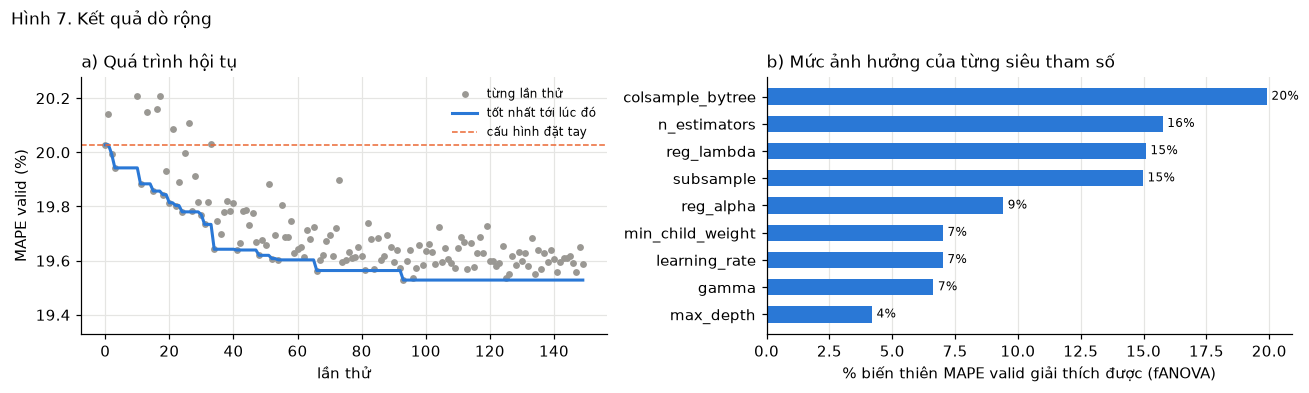

In [17]:
wide, wide_df = load_or_run(WIDE_CSV, WIDE_SPACE, WIDE_TRIALS,
                            CURRENT_PARAMS | {"reg_alpha": 1e-3, "gamma": 1e-3}, "Dò rộng")
print(f"MAPE valid: cấu hình đặt tay (lần 0) {wide_df.valid_mape.iloc[0]:.2%} -> tốt nhất {wide.best_value:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(wide_df.index, wide_df.valid_mape * 100, s=12, color=GRAY, label="từng lần thử")
axes[0].plot(wide_df.index, wide_df.valid_mape.cummin() * 100, color=BLUE, lw=2, label="tốt nhất tới lúc đó")
axes[0].axhline(wide_df.valid_mape.iloc[0] * 100, color=ORANGE, ls="--", lw=1, label="cấu hình đặt tay")
axes[0].set_ylim(wide_df.valid_mape.min() * 100 - 0.2, wide_df.valid_mape.quantile(0.95) * 100)
axes[0].set_xlabel("lần thử"); axes[0].set_ylabel("MAPE valid (%)")
axes[0].set_title("a) Quá trình hội tụ"); axes[0].legend(frameon=False, fontsize=8)
imp = pd.Series(optuna.importance.get_param_importances(wide)).sort_values()
bars = axes[1].barh(imp.index, imp.values * 100, color=BLUE, height=0.6)
axes[1].bar_label(bars, labels=[f"{v * 100:.0f}%" for v in imp.values], padding=3, fontsize=8)
axes[1].set_xlabel("% biến thiên MAPE valid giải thích được (fANOVA)"); axes[1].grid(axis="y", visible=False)
axes[1].set_title("b) Mức ảnh hưởng của từng siêu tham số")
fig.suptitle("Hình 7. Kết quả dò rộng", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**Nhận xét.** MAPE valid giảm từ 20,03% (cấu hình đặt tay) xuống 19,53% sau 150 lần thử; đường "tốt nhất tới lúc đó" gần như đi ngang sau khoảng
lần thử 90, cho thấy tìm kiếm đã hội tụ. Các lần thử tốt nhất đều dùng nhiều cây (1.700–1.900) với tốc độ học nhỏ (≈ 0,015),
cây sâu (9–10), lấy mẫu 65–70% dòng và 84–90% cột, phạt L2 nhẹ. Tỉ lệ cột (`colsample_bytree`), số cây và hai tham số điều chuẩn
có ảnh hưởng lớn nhất; độ sâu cây ảnh hưởng ít vì vùng tốt của nó đã rõ ngay từ đầu (9–10).

### 7.2 Dò hẹp quanh vùng tốt

In [18]:
top = wide_df.nsmallest(TOP_K, "valid_mape")
NARROW_SPACE = {}
for name, (lo, hi, log, step) in WIDE_SPACE.items():
    n_lo, n_hi = top[name].min(), top[name].max()
    if name in INT_PARAMS:
        n_lo, n_hi = int(n_lo), int(max(n_hi, n_lo + (step or 1)))
    elif n_hi <= n_lo:
        n_hi = n_lo * 1.01 if log else n_lo + 1e-3
    NARROW_SPACE[name] = (n_lo, n_hi, log, step)
display(pd.DataFrame({"vùng dò rộng": [f"{v[0]:g} – {v[1]:g}" for v in WIDE_SPACE.values()],
                      f"vùng dò hẹp (top {TOP_K})": [f"{v[0]:.4g} – {v[1]:.4g}" for v in NARROW_SPACE.values()]},
                     index=list(WIDE_SPACE)))

narrow, narrow_df = load_or_run(NARROW_CSV, NARROW_SPACE, NARROW_TRIALS, wide.best_params, "Dò hẹp")
BEST_PARAMS = narrow.best_params if narrow.best_value <= wide.best_value else wide.best_params
pd.DataFrame({"đặt tay": pd.Series(CURRENT_PARAMS), "sau khi dò": pd.Series(BEST_PARAMS)})

,vùng dò rộng,vùng dò hẹp (top 15)
n_estimators,400 – 2000,1700 – 1900
learning_rate,0.01 – 0.1,0.01361 – 0.02069
max_depth,4 – 10,9 – 10
min_child_weight,1 – 20,2 – 5
subsample,0.6 – 1,0.6561 – 0.706
colsample_bytree,0.4 – 1,0.8373 – 0.9002
reg_lambda,0.1 – 10,0.1035 – 0.1501
reg_alpha,0.001 – 5,0.06554 – 0.3986
gamma,0.001 – 1,0.00113 – 0.007829


Dò hẹp: 40 lần thử (từ optuna_narrow_search.csv), tốt nhất 19.52% ở lần 36


,đặt tay,sau khi dò
colsample_bytree,0.7000,0.8417
gamma,NaN,0.0076
learning_rate,0.0500,0.0152
max_depth,7.0000,10.0000
min_child_weight,5.0000,4.0000
n_estimators,800.0000,"1,800.0000"
reg_alpha,NaN,0.1407
reg_lambda,1.0000,0.1406
subsample,0.8000,0.6731


## 8. Đánh giá trên tập kiểm tra

Bây giờ mới dùng tập test. Bốn cấu hình kết hợp hai thử nghiệm (lọc nhiễu, siêu tham số mới), mỗi cấu hình fit lại trên toàn bộ train.
XGBoost có yếu tố ngẫu nhiên (lấy mẫu dòng, cột), nên mỗi cấu hình chạy **3 seed**; độ lệch chuẩn giữa các seed cho biết
chênh lệch bao nhiêu thì mới đáng tin.

In [19]:
SEEDS = [42, 7, 123]
actual = test["price_vnd"].to_numpy()


def evaluate(predict_fn):
    # predict_fn(seed) -> giá dự đoán cho test. Trả về chỉ số trung bình 3 seed và sai số từng tin.
    preds = [np.asarray(predict_fn(s)) for s in SEEDS]
    mapes = [mape(p, test) for p in preds]
    ape = np.abs(np.mean(preds, axis=0) - actual) / actual
    return {"MAPE": np.mean(mapes), "độ lệch 3 seed": np.std(mapes), "MdAPE": np.median(ape),
            "sai ≤ 20%": (ape <= 0.20).mean()}, pd.Series(ape, index=test.index)


EXPERIMENTS = {
    "A. Đặt tay":                (train,          CURRENT_PARAMS),
    "B. Lọc nhiễu":              (train_filtered, CURRENT_PARAMS),
    "C. Tham số mới":            (train,          BEST_PARAMS),
    "D. Lọc nhiễu + tham số mới": (train_filtered, BEST_PARAMS),
}
rows, ape_by_exp = {}, {}
for name, (fit, params) in EXPERIMENTS.items():
    rows[name], ape_by_exp[name] = evaluate(lambda s: fit_predict(fit, test, params, s))
results = pd.DataFrame(rows).T
results["giảm so với A (điểm %)"] = (results.loc["A. Đặt tay", "MAPE"] - results["MAPE"]) * 100
by_type = pd.DataFrame({n: a.groupby(test["property_type"]).mean() * 100 for n, a in ape_by_exp.items()}).T[types]
display(results.style.format({"MAPE": "{:.2%}", "độ lệch 3 seed": "{:.2%}", "MdAPE": "{:.2%}",
                              "sai ≤ 20%": "{:.1%}", "giảm so với A (điểm %)": "{:+.2f}"}))
print("MAPE (%) theo loại hình; số tin test:", test["property_type"].value_counts().to_dict())
by_type.round(2)

,MAPE,độ lệch 3 seed,MdAPE,sai ≤ 20%,giảm so với A (điểm %)
A. Đặt tay,19.57%,0.03%,13.17%,67.3%,+0.00
B. Lọc nhiễu,19.62%,0.06%,13.14%,67.6%,-0.05
C. Tham số mới,19.21%,0.07%,12.79%,67.9%,+0.36
D. Lọc nhiễu + tham số mới,19.26%,0.02%,12.99%,68.0%,+0.31


MAPE (%) theo loại hình; số tin test: {'Nhà ở': 7012, 'Căn hộ/Chung cư': 1232, 'Đất': 1005}


property_type,Căn hộ/Chung cư,Nhà ở,Đất
A. Đặt tay,13.2200,19.1900,28.8000
B. Lọc nhiễu,13.1900,19.0900,29.9400
C. Tham số mới,12.6900,18.8200,29.3100
D. Lọc nhiễu + tham số mới,12.6300,18.7600,30.2300


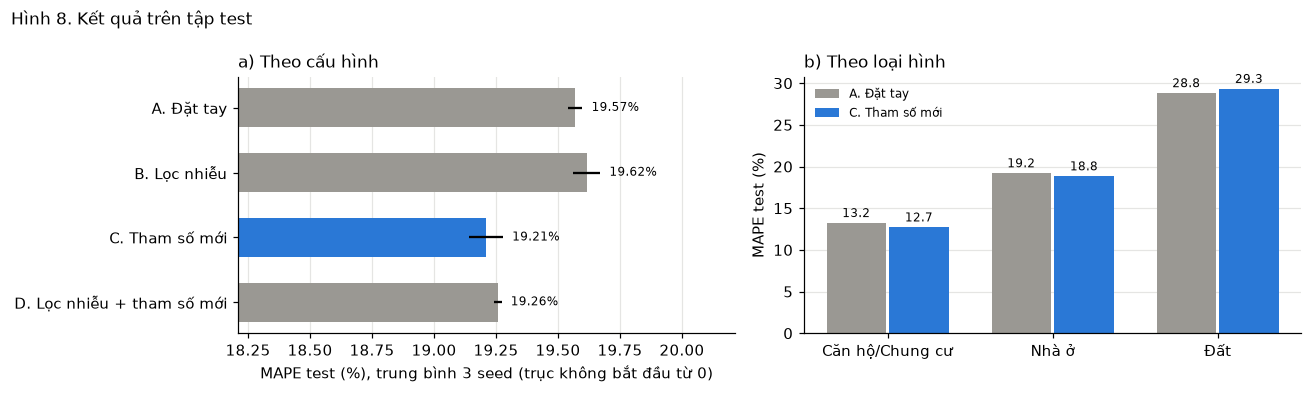

In [20]:
best_name = results["MAPE"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot = results["MAPE"] * 100
bars = axes[0].barh(plot.index[::-1], plot.values[::-1], xerr=results["độ lệch 3 seed"].values[::-1] * 100,
                    color=[BLUE if n == best_name else GRAY for n in plot.index[::-1]], height=0.6)
axes[0].bar_label(bars, labels=[f"{v:.2f}%" for v in plot.values[::-1]], padding=6, fontsize=8)
axes[0].set_xlim(plot.min() - 1, plot.max() + 0.6); axes[0].grid(axis="y", visible=False)
axes[0].set_xlabel("MAPE test (%), trung bình 3 seed (trục không bắt đầu từ 0)"); axes[0].set_title("a) Theo cấu hình")
x = np.arange(len(types))
for i, (name, color) in enumerate([("A. Đặt tay", GRAY), (best_name, BLUE)]):
    b = axes[1].bar(x + (i - 0.5) * 0.38, by_type.loc[name, types], width=0.36, color=color, label=name)
    axes[1].bar_label(b, labels=[f"{v:.1f}" for v in by_type.loc[name, types]], padding=2, fontsize=8)
axes[1].set_xticks(x, types); axes[1].set_ylabel("MAPE test (%)"); axes[1].grid(axis="x", visible=False)
axes[1].set_title("b) Theo loại hình"); axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Hình 8. Kết quả trên tập test", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**Nhận xét.**
- **Siêu tham số mới (C)** giảm MAPE test từ 19,57% xuống 19,21% (−0,36 điểm), lớn hơn 5 lần dao động giữa các seed (±0,07),
  nên là cải thiện thật. MdAPE giảm từ 13,17% xuống 12,79%. Căn hộ (13,22% → 12,69%) và nhà ở (19,19% → 18,82%) cùng giảm.
  Đất tăng nhẹ (28,80% → 29,31%) nhưng chỉ có 1.005 tin test với sai số rất lệch, mức dao động này nằm trong nhiễu.
- **Lọc nhiễu (B, D)** chỉ bỏ 35 tin (0,09%) và làm MAPE tăng nhẹ 0,05 điểm: bước lọc ngoại lai ở dbt đã đủ, nên không đưa bước này vào pipeline.
- Cấu hình được chọn: **C**. Bộ tham số này (sau khi dò hẹp) gần như trùng với `TUNED_PARAMS` đang dùng trong pipeline
  (chênh trong mức nhiễu), nên pipeline giữ nguyên `TUNED_PARAMS` làm lần thử 0 và mỗi lần huấn luyện dò thêm 30 lần quanh đó.

## 9. Một mô hình gộp hay mô hình riêng cho từng loại hình

Căn hộ, nhà ở và đất có cơ chế hình thành giá khác nhau, nên một câu hỏi tự nhiên là có nên huấn luyện riêng mỗi loại một mô hình.

- **Gộp**: một mô hình học trên toàn bộ train, dự đoán toàn bộ test. Cây vẫn tách nhánh theo `property_type` khi cần,
  và dùng chung được thông tin vị trí giữa các loại (khu vực đắt thì cả căn hộ lẫn đất đều đắt).
- **Riêng**: mỗi loại hình một mô hình, chỉ học trên tin loại đó và chỉ dự đoán tin loại đó.
  Mô hình chuyên biệt hơn nhưng có ít dữ liệu hơn (căn hộ và đất chỉ vài nghìn tin).

Cùng cấu hình tốt nhất ở mục 8, cùng tập test, 3 seed.

Số tin train theo loại: {'Nhà ở': 28276, 'Căn hộ/Chung cư': 5868, 'Đất': 5235}


,MAPE,độ lệch 3 seed,MdAPE,sai ≤ 20%
Gộp (một mô hình),19.21%,0.07%,12.79%,67.9%
Riêng từng loại (3 mô hình),19.21%,0.03%,12.66%,68.8%


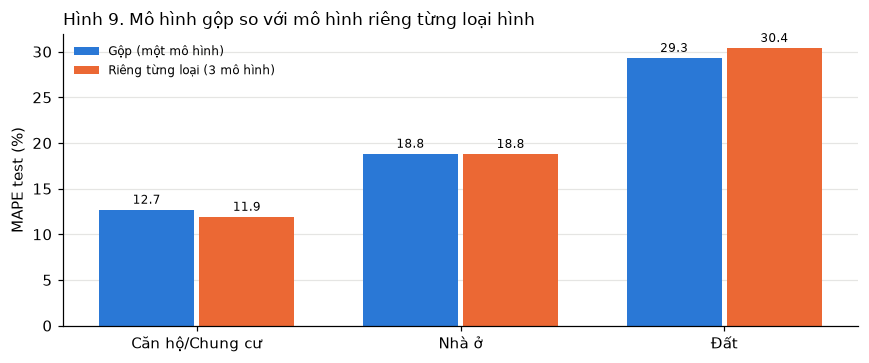

property_type,Căn hộ/Chung cư,Nhà ở,Đất,Tất cả
Gộp (một mô hình),12.6900,18.8200,29.3100,19.2100
Riêng từng loại (3 mô hình),11.9200,18.8000,30.4000,19.2100


In [21]:
BEST_TRAIN, BEST_P = EXPERIMENTS[best_name]
print("Số tin train theo loại:", BEST_TRAIN["property_type"].value_counts().to_dict())


def predict_separate(seed):
    pred = pd.Series(np.nan, index=test.index)
    for t in types:
        tr, te = BEST_TRAIN[BEST_TRAIN.property_type == t], test[test.property_type == t]
        pred.loc[te.index] = fit_predict(tr, te, BEST_P, seed)
    return pred.to_numpy()


split_rows, split_ape = {}, {}
split_rows["Gộp (một mô hình)"], split_ape["Gộp (một mô hình)"] = evaluate(
    lambda s: fit_predict(BEST_TRAIN, test, BEST_P, s))
split_rows["Riêng từng loại (3 mô hình)"], split_ape["Riêng từng loại (3 mô hình)"] = evaluate(predict_separate)
split_results = pd.DataFrame(split_rows).T
split_by_type = pd.DataFrame({n: a.groupby(test["property_type"]).mean() * 100 for n, a in split_ape.items()}).T[types]
split_by_type["Tất cả"] = split_results["MAPE"] * 100
display(split_results.style.format({"MAPE": "{:.2%}", "độ lệch 3 seed": "{:.2%}", "MdAPE": "{:.2%}", "sai ≤ 20%": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, color) in enumerate(zip(split_by_type.index, [BLUE, ORANGE])):
    b = ax.bar(x + (i - 0.5) * 0.38, split_by_type.loc[name, types], width=0.36, color=color, label=name)
    ax.bar_label(b, labels=[f"{v:.1f}" for v in split_by_type.loc[name, types]], padding=2, fontsize=8)
ax.set_xticks(x, types); ax.set_ylabel("MAPE test (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Hình 9. Mô hình gộp so với mô hình riêng từng loại hình"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
split_by_type.round(2)

**Nhận xét.** Tổng thể hai cách cho cùng MAPE 19,21%. Mô hình riêng tốt hơn cho căn hộ (12,69% → 11,92%), nhưng kém hơn cho đất (29,31% → 30,40%),
còn nhà ở như nhau. Phần lợi ở căn hộ bị bù trừ bởi phần thiệt ở đất: mô hình riêng cho đất chỉ có 5.235 tin để học và mất thông tin giá
khu vực từ nhà ở cùng phường. Vì độ chính xác như nhau, **chọn một mô hình gộp**: chỉ một lần huấn luyện, một cổng chất lượng,
một phiên bản trong MLflow và một mô hình trong API.

## 10. Phân tích mô hình cuối cùng

Mô hình cuối (cấu hình tốt nhất ở mục 8, một mô hình gộp, seed 42) được fit lại trên train để xem nó sai ở đâu và dựa vào đặc trưng nào.

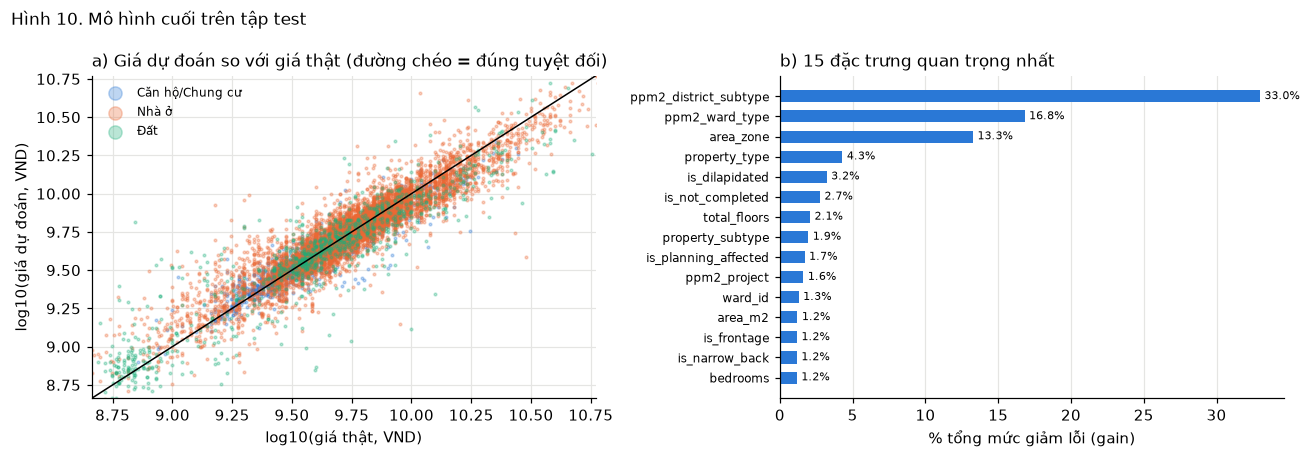

,so_tin,MAPE,MdAPE,độ lệch trung vị (dự đoán/thật − 1)
khoảng giá,,,,
< 2 tỷ,789,44.00%,24.07%,+18.1%
2–4 tỷ,"2,356",17.97%,11.67%,+4.4%
4–7 tỷ,"3,459",14.92%,11.18%,+0.3%
7–12 tỷ,"1,728",16.09%,12.80%,-4.9%
12–20 tỷ,614,21.29%,19.11%,-14.4%
> 20 tỷ,303,25.46%,23.27%,-21.6%


In [22]:
final = build_model(BEST_P, 42).fit(prepare(BEST_TRAIN), np.log(BEST_TRAIN["price_vnd"]))
final_pred = np.exp(final.predict(prepare(test)))
err = test[["property_type", "price_vnd"]].assign(pred=final_pred,
                                                  ape=np.abs(final_pred - actual) / actual)
err["khoảng giá"] = pd.cut(err.price_vnd / 1e9, [0, 2, 4, 7, 12, 20, np.inf],
                           labels=["< 2 tỷ", "2–4 tỷ", "4–7 tỷ", "7–12 tỷ", "12–20 tỷ", "> 20 tỷ"])
err["bias"] = err.pred / err.price_vnd - 1
by_bucket = err.groupby("khoảng giá", observed=True).agg(so_tin=("ape", "size"), MAPE=("ape", "mean"),
                                                         MdAPE=("ape", "median"), bias=("bias", "median"))
by_bucket = by_bucket.rename(columns={"bias": "độ lệch trung vị (dự đoán/thật − 1)"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
lim = [np.log10(err.price_vnd.quantile(0.002)), np.log10(err.price_vnd.quantile(0.998))]
for t in types:
    e = err[err.property_type == t]
    axes[0].scatter(np.log10(e.price_vnd), np.log10(e.pred), s=3, alpha=0.3, color=TYPE_COLOR[t], label=t)
axes[0].plot(lim, lim, color="black", lw=1); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("log10(giá thật, VND)"); axes[0].set_ylabel("log10(giá dự đoán, VND)")
axes[0].set_title("a) Giá dự đoán so với giá thật (đường chéo = đúng tuyệt đối)")
axes[0].legend(frameon=False, fontsize=8, markerscale=5)

names = final.named_steps["prep"].get_feature_names_out()
importance = pd.Series(final.named_steps["model"].feature_importances_, index=names).nlargest(15).sort_values()
bars = axes[1].barh(importance.index, importance.values * 100, color=BLUE, height=0.6)
axes[1].bar_label(bars, labels=[f"{v * 100:.1f}%" for v in importance.values], padding=3, fontsize=7)
axes[1].set_xlabel("% tổng mức giảm lỗi (gain)"); axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=8); axes[1].set_title("b) 15 đặc trưng quan trọng nhất")
fig.suptitle("Hình 10. Mô hình cuối trên tập test", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
by_bucket.style.format({"so_tin": "{:,.0f}", "MAPE": "{:.2%}", "MdAPE": "{:.2%}",
                        "độ lệch trung vị (dự đoán/thật − 1)": "{:+.1%}"})

In [23]:
land = test[test.property_type == "Đất"].assign(ape=err["ape"])
land_sub = land.groupby("property_subtype").agg(so_tin=("ape", "size"), MAPE=("ape", "mean"), MdAPE=("ape", "median"))
land_size = land.groupby(pd.cut(land.area_m2, [0, 100, 200, 500, np.inf],
                                labels=["≤ 100 m²", "100–200 m²", "200–500 m²", "> 500 m²"]), observed=True
                         ).agg(so_tin=("ape", "size"), MAPE=("ape", "mean"), MdAPE=("ape", "median"))
print("Đất: sai số theo loại con và theo diện tích")
display(land_sub.style.format({"MAPE": "{:.1%}", "MdAPE": "{:.1%}"}))
land_size.style.format({"MAPE": "{:.1%}", "MdAPE": "{:.1%}"})

Đất: sai số theo loại con và theo diện tích


,so_tin,MAPE,MdAPE
property_subtype,,,
Đất công nghiệp,5,191.8%,40.3%
Đất nông nghiệp,80,50.5%,31.1%
Đất nền dự án,38,23.4%,15.1%
Đất thổ cư,882,26.5%,16.3%


,so_tin,MAPE,MdAPE
area_m2,,,
≤ 100 m²,472,22.7%,12.7%
100–200 m²,262,31.8%,19.8%
200–500 m²,168,31.3%,22.1%
> 500 m²,103,48.3%,34.2%


**Nhận xét.**
- Phần lớn điểm nằm sát đường chéo. Nhóm đặc trưng giá khu vực chiếm khoảng một nửa tổng mức giảm lỗi
  (`ppm2_district_subtype` 33%, `ppm2_ward_type` 17%), tiếp theo là `area_zone` (nội thành / ngoại thành). Điều này khớp với mục 2.3: vị trí quyết định giá.
- Mô hình có xu hướng **kéo về giữa**: tin dưới 2 tỷ bị đoán cao (lệch trung vị +18%), tin trên 20 tỷ bị đoán thấp (−22%).
  Ở khoảng 4–12 tỷ, nơi tập trung 56% số tin, MAPE chỉ 15–16%.
- Sai số lớn của đất đến từ đất nông nghiệp (MAPE 50%) và lô lớn trên 500 m² (48%). Đất thổ cư dưới 100 m² có MAPE 23%, gần với nhà ở.
  Nguyên nhân: giá đất lớn phụ thuộc phần diện tích được lên thổ cư và quy hoạch, những thông tin chỉ có trong mô tả tự do, không có trong dữ liệu có cấu trúc.

## 11. Kết luận

In [24]:
base = first.iloc[0]
a, b = results.loc["A. Đặt tay"], results.loc[best_name]
noise = max(a["độ lệch 3 seed"], b["độ lệch 3 seed"]) * 100
print(f"Mô hình cơ sở          : MAPE {base.MAPE:.2%} | MdAPE {base.MdAPE:.2%} | {base['sai ≤ 20%']:.1%} tin sai ≤ 20%")
print(f"XGBoost đặt tay        : MAPE {a.MAPE:.2%} | MdAPE {a.MdAPE:.2%} | {a['sai ≤ 20%']:.1%} tin sai ≤ 20%")
print(f"{best_name:<23}: MAPE {b.MAPE:.2%} | MdAPE {b.MdAPE:.2%} | {b['sai ≤ 20%']:.1%} tin sai ≤ 20%")
print(f"Dò tham số giảm {(a.MAPE - b.MAPE) * 100:.2f} điểm MAPE, dao động giữa các seed ±{noise:.2f} điểm "
      f"-> {'có ý nghĩa' if (a.MAPE - b.MAPE) * 100 >= 3 * noise else 'trong mức nhiễu'} (ngưỡng 3 lần dao động).")
g, r = split_results.iloc[0], split_results.iloc[1]
print(f"Gộp {g.MAPE:.2%} so với riêng {r.MAPE:.2%}: chênh {(r.MAPE - g.MAPE) * 100:+.2f} điểm.")
print("\nSiêu tham số cho TUNED_PARAMS trong scripts/train_price_model.py:")
for k, v in BEST_P.items():
    print(f"    {k} = {round(v, 4) if isinstance(v, float) else v}")

Mô hình cơ sở          : MAPE 35.01% | MdAPE 22.48% | 45.6% tin sai ≤ 20%
XGBoost đặt tay        : MAPE 19.57% | MdAPE 13.17% | 67.3% tin sai ≤ 20%
C. Tham số mới         : MAPE 19.21% | MdAPE 12.79% | 67.9% tin sai ≤ 20%
Dò tham số giảm 0.36 điểm MAPE, dao động giữa các seed ±0.07 điểm -> có ý nghĩa (ngưỡng 3 lần dao động).
Gộp 19.21% so với riêng 19.21%: chênh +0.00 điểm.

Siêu tham số cho TUNED_PARAMS trong scripts/train_price_model.py:
    n_estimators = 1800
    learning_rate = 0.0152
    max_depth = 10
    min_child_weight = 4
    subsample = 0.6731
    colsample_bytree = 0.8417
    reg_lambda = 0.1406
    reg_alpha = 0.1407
    gamma = 0.0076


**Tóm tắt.**

1. **Dữ liệu**: 48.628 tin bán sau làm sạch (90,6% số tin bán thu thập được), qua 7 bước lọc ở tầng Gold: điều kiện tối thiểu, ngoại lai,
   vị trí không tin cậy, tin trùng, văn phòng/mặt bằng.
2. **Tiền xử lý**: không điền giá trị thiếu (đa số thiếu theo cấu trúc); mã hoá thứ tự cho 9 biến ít mức, mã hoá mục tiêu chéo cho phường, đường, dự án;
   thêm 8 đặc trưng giá khu vực tính ngoài fold; mô hình học log(giá/m²).
3. **Đánh giá**: chia theo thời gian, test là 20% tin mới nhất (9.249 tin), không dùng để chọn tham số.
4. **Kết quả**: XGBoost sau khi dò siêu tham số đạt **MAPE 19,21%, MdAPE 12,79%, 67,9% tin sai không quá 20%**,
   so với 35,01% của mô hình cơ sở. Theo loại hình: căn hộ 12,7%, nhà ở 18,8%, đất 29,3%.
5. **Các phương án đã thử nhưng không chọn**: lọc nhiễu cục bộ (không cải thiện), mô hình riêng cho từng loại hình (không hơn mô hình gộp).

**Hạn chế.** Dữ liệu mới thu thập khoảng 2,5 tháng nên chưa đánh giá được độ ổn định của mô hình khi thị trường biến động.
Đất, nhất là đất nông nghiệp và lô lớn, còn sai số cao vì thiếu thông tin về phần diện tích thổ cư.
Mô hình có xu hướng định giá thấp bất động sản rất đắt (trên 20 tỷ), là nhóm ít tin.

**Hướng phát triển.** Trích xuất diện tích thổ cư, quy hoạch từ phần mô tả tin đăng; theo dõi sai số theo thời gian khi dữ liệu dài hơn
(pipeline đã huấn luyện lại hằng tuần và chỉ thay mô hình khi tốt hơn trên cùng tập test).